# 01 — Exploration des données (EDA) : HAM10000

**Projet :** Classification des lésions cutanées et Explainable AI (XAI)  
**Dataset :** HAM10000 — 10 015 images, 7 classes  
**Environnement :** Kaggle / Python

## Objectifs

- Vérifier le chargement des images et la qualité des métadonnées.
- Comprendre la distribution des diagnostics et les différences d'effectifs entre les classes.
- Examiner les images et les informations descriptives utiles pour évaluer les limites du jeu de données.
- Identifier les risques de fuite de données avant de construire les ensembles Train, Validation et Test.

**Périmètre :** ce projet entraîne des modèles sur les **images**. Les métadonnées d'âge et de sexe servent ici à décrire le dataset, pas d'entrées supplémentaires des modèles. Les figures et statistiques ne permettent pas de conclure à une validité clinique.

## 1. Bibliothèques et chemins Kaggle

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Chemin du dataset HAM10000 sur Kaggle
DATA_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000"
)

# Dossier contenant les images
IMAGES_DIR = DATA_DIR / "images"

# Dossier pour sauvegarder les graphiques
FIGURES_DIR = Path("/kaggle/working/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset :", DATA_DIR)
print("Images :", IMAGES_DIR)
print("Graphiques :", FIGURES_DIR)

Dataset : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000
Images : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000/images
Graphiques : /kaggle/working/figures


## 2. Chargement et validation du dataset

In [2]:
# 1. Vérifier la présence du dataset
metadata_path = DATA_DIR / "HAM10000_metadata.csv"

if not metadata_path.exists():
    raise FileNotFoundError("Fichier HAM10000_metadata.csv introuvable.")

if not IMAGES_DIR.is_dir():
    raise FileNotFoundError("Dossier images introuvable.")


# 2. Charger les métadonnées
df = pd.read_csv(metadata_path)


# 3. Vérifier les colonnes obligatoires
required_columns = ["image_id", "lesion_id", "dx"]

for column in required_columns:
    if column not in df.columns:
        raise ValueError(f"Colonne manquante : {column}")


# 4. Vérifier les valeurs manquantes
if df[required_columns].isnull().any().any():
    raise ValueError("Valeurs manquantes dans les colonnes obligatoires.")


# 5. Vérifier les identifiants des images
if df["image_id"].duplicated().any():
    raise ValueError("Des image_id sont dupliqués dans le CSV.")


# 6. Récupérer les fichiers images
image_files = [
    path for path in IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Vérifier les doublons de noms d'images
image_ids = [path.stem for path in image_files]

if len(image_ids) != len(set(image_ids)):
    raise ValueError("Plusieurs fichiers possèdent le même image_id.")


# 7. Associer chaque image à son chemin
image_paths = {
    path.stem: path for path in image_files
}

df["image_path"] = df["image_id"].map(image_paths)

# Vérifier que toutes les images sont retrouvées
if df["image_path"].isnull().any():
    raise FileNotFoundError("Certaines images du CSV sont introuvables.")


# 8. Définir les sept classes
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

if set(df["dx"].unique()) != set(CLASSES):
    raise ValueError("Les classes du dataset ne correspondent pas aux 7 classes attendues.")


# 9. Convertir les classes en labels numériques
class_to_idx = {
    classe: index for index, classe in enumerate(CLASSES)
}

df["label"] = df["dx"].map(class_to_idx).astype(int)


# 10. Afficher le résumé du dataset
print("Nombre d'images :", len(df))
print("Images indexées :", len(image_files))
print("Nombre de classes :", df["dx"].nunique())
print("Lésions uniques :", df["lesion_id"].nunique())
print("Images manquantes :", df["image_path"].isnull().sum())

if len(df) != 10015:
    print("Attention : HAM10000 devrait contenir 10 015 images.")

print("\nEncodage des classes :")
print(class_to_idx)

display(df.head())

Nombre d'images : 10015
Images indexées : 10015
Nombre de classes : 7
Lésions uniques : 7470
Images manquantes : 0

Encodage des classes :
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2


- Les contrôles ont identifié **10 015 lignes**, **10 015 images indexées**, **7 diagnostics** et **7 470 lésions uniques**. Aucune image référencée dans les métadonnées n'est manquante. Les étiquettes sont encodées ainsi : `akiec=0`, `bcc=1`, `bkl=2`, `df=3`, `mel=4`, `nv=5`, `vasc=6`.

> **Interprétation :** le nombre de lésions (7 470) est inférieur au nombre d'images (10 015). Il faut donc prévoir une séparation des données **par `lesion_id`** plutôt que par image.

## 3. Qualité des métadonnées et répétition des lésions

In [3]:
# 1. Dimensions du DataFrame
print("Dimensions du DataFrame :", df.shape)
display(df.head())


# 2. Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df.isnull().sum())


# 3. Analyser les méthodes de confirmation du diagnostic
print("\nMéthodes de confirmation des diagnostics :")
print(df["dx_type"].value_counts())


# 4. Compter les images associées à chaque lésion
images_per_lesion = df.groupby("lesion_id").size()

print("\nStatistiques des images par lésion :")
print(images_per_lesion.describe())

# Nombre de lésions possédant plusieurs images
multiple_lesions = (images_per_lesion > 1).sum()

print("\nLésions avec plusieurs images :", multiple_lesions)

Dimensions du DataFrame : (10015, 9)


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2



Valeurs manquantes :
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
image_path       0
label            0
dtype: int64

Méthodes de confirmation des diagnostics :
dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64

Statistiques des images par lésion :
count    7470.000000
mean        1.340696
std         0.633970
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         6.000000
dtype: float64

Lésions avec plusieurs images : 1956


- Cette étape vise à distinguer une photographie (une **image**) d'une lésion (un **groupe d'images potentiellement associées**).

> un split aléatoire des images peut placer deux vues d'une même lésion dans des ensembles différents, créant une fuite de données et une évaluation trop optimiste. Le prochain notebook appliquera un **GroupSplit par `lesion_id`**. Le dataset ne fournit pas ici de clé `patient_id` permettant de garantir une séparation par patient.

## 4. Distribution des sept classes

,Classe,Images,Pourcentage (%)
0,akiec,327,3.27
1,bcc,514,5.13
2,bkl,1099,10.97
3,df,115,1.15
4,mel,1113,11.11
5,nv,6705,66.95
6,vasc,142,1.42


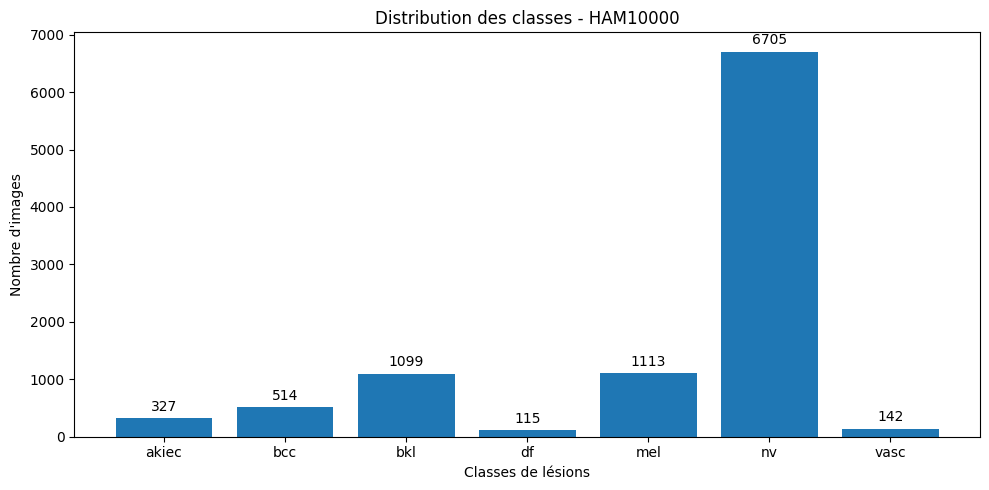

In [4]:
# 1. Compter les images de chaque classe
counts = df["dx"].value_counts().reindex(CLASSES)

# 2. Créer un tableau avec les effectifs et les pourcentages
summary = pd.DataFrame({
    "Classe": CLASSES,
    "Images": counts.values,
    "Pourcentage (%)": (counts.values / len(df) * 100).round(2)
})

display(summary)

# 3. Créer le graphique
plt.figure(figsize=(10, 5))

bars = plt.bar(summary["Classe"], summary["Images"])

plt.title("Distribution des classes - HAM10000")
plt.xlabel("Classes de lésions")
plt.ylabel("Nombre d'images")

# 4. Afficher le nombre d'images au-dessus de chaque barre
plt.bar_label(bars, padding=3)

plt.tight_layout()

# 5. Sauvegarder le graphique
plt.savefig(
    FIGURES_DIR / "eda_class_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

- La classe `nv` est très majoritaire : elle représente **environ deux images sur trois**. À l'inverse, `df`, `vasc` et `akiec` disposent de peu d'exemples. Un modèle peut obtenir une accuracy élevée en favorisant `nv` tout en reconnaissant mal certaines classes minoritaires. Le mélanome (`mel`) est également sous-représenté par rapport à `nv`, ce qui impose de surveiller son **rappel**.

>**Décision pour le projet :** calculer des **class weights uniquement sur les images Train**, puis les transmettre à `torch.nn.CrossEntropyLoss(weight=...)`. Évaluer ensuite les performances du modèle avec le **Macro-F1**, le rappel par classe et la matrice de confusion afin de vérifier si cette pondération améliore les résultats sur Validation.

## 5. Exemples visuels par diagnostic

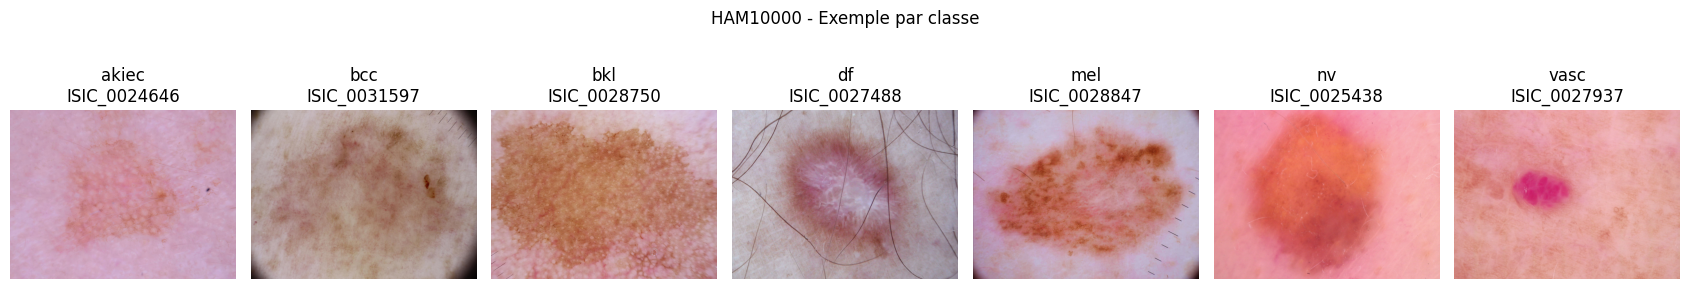

In [5]:
# 1. Créer une figure contenant 7 images
fig, axes = plt.subplots(1, 7, figsize=(17, 3.5))

# 2. Parcourir les 7 classes
for ax, classe in zip(axes, CLASSES):

    # Sélectionner une image aléatoire de la classe
    sample = df[df["dx"] == classe].sample(
        n=1, random_state=42
    ).iloc[0]

    # Ouvrir et afficher l'image
    with Image.open(sample["image_path"]) as image:
        ax.imshow(image.convert("RGB"))

    # Afficher la classe et l'identifiant de l'image
    ax.set_title(f"{classe}\n{sample['image_id']}")
    ax.axis("off")

# 3. Ajouter le titre général
fig.suptitle("HAM10000 - Exemple par classe")

plt.tight_layout()

# 4. Sauvegarder la figure
plt.savefig(
    FIGURES_DIR / "eda_class_examples.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 6. Métadonnées descriptives : âge et sexe

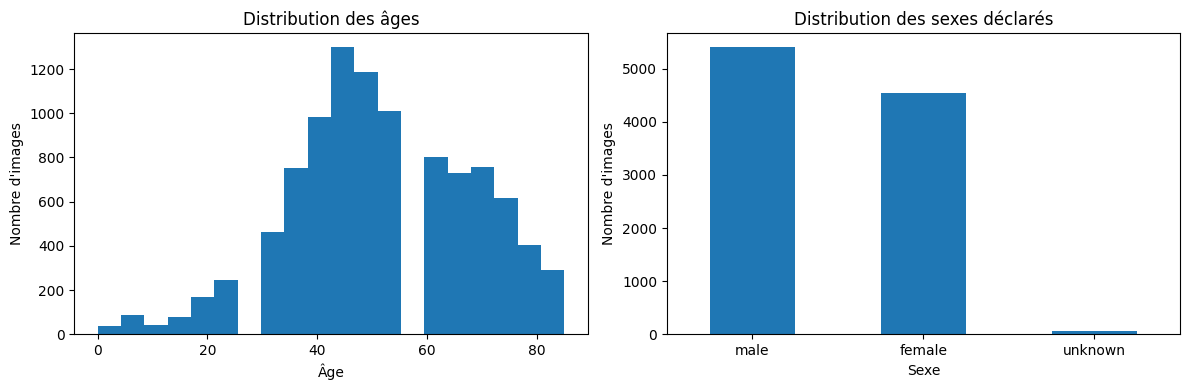

In [6]:
# 1. Créer une figure avec deux graphiques
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 2. Distribution des âges (sans les valeurs manquantes)
axes[0].hist(df["age"].dropna(), bins=20)

axes[0].set_title("Distribution des âges")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Nombre d'images")

# 3. Distribution des sexes déclarés
sex_counts = df["sex"].fillna("unknown").value_counts()

sex_counts.plot(kind="bar", ax=axes[1])

axes[1].set_title("Distribution des sexes déclarés")
axes[1].set_xlabel("Sexe")
axes[1].set_ylabel("Nombre d'images")
axes[1].tick_params(axis="x", rotation=0)

# 4. Ajuster et sauvegarder la figure
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "eda_metadata.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

L'histogramme fourni montre une concentration importante d'images autour des **âges moyens et élevés**, avec relativement peu d'images dans les âges les plus jeunes. Le graphique des sexes déclarés montre **un peu plus d'images étiquetées `male` que `female`**, et très peu d'images dans la catégorie `unknown`.

>Ces graphiques signalent de possibles **déséquilibres de représentation**, mais ne prouvent pas à eux seuls un biais de prédiction. Il faudrait mesurer les performances par sous-groupe et contrôler les différences de diagnostic et les images répétées pour tester une telle hypothèse. Pour notre objectif principal — classification des sept classes — cette partie reste descriptive.

## 7. Analyse personnelle — Réponses aux questions

### 1. Quelle classe représente la majorité des images ? Quelle est sa proportion ?

La classe **`nv`** est majoritaire avec **6 705 images sur 10 015**, soit **66,95 %** du dataset. Elle domine donc très largement la distribution des diagnostics.

### 2. Quelles classes risquent d'être mal apprises sans traitement du déséquilibre ?

Les classes les moins représentées sont particulièrement exposées : **`df` (115 images ; 1,15 %)**, **`vasc` (142 ; 1,42 %)** et **`akiec` (327 ; 3,27 %)**. Les classes `bcc` et `mel` ont également beaucoup moins d'images que `nv` , pour le **mélanome (`mel`, 1 113 images ; 11,11 %)**, un faible rappel serait spécialement préoccupant dans l'analyse des erreurs. Ce sont des **risques à vérifier expérimentalement**, pas des performances déjà mesurées.

Pour limiter ce problème, le projet calculera les **poids de classes à partir du Train seulement**, puis utilisera une perte `CrossEntropyLoss` pondérée. Nous analyserons le macro-F1 et les rappels par classe, plutôt que de nous limiter à l'accuracy.

### 3. Quel est le nombre de lésions uniques ? Certaines possèdent-elles plusieurs images ?

Le dataset contient **7 470 lésions uniques (`lesion_id`)** pour **10 015 images**. Parmi elles, **1 956 lésions** possèdent plusieurs photographies , une lésion peut être associée à **6 images au maximum**. Les données ne peuvent donc pas être considérées comme 10 015 lésions indépendantes.

### 4. Pourquoi une séparation aléatoire par image peut-elle créer une fuite de données ?

Deux images portant le **même `lesion_id`** peuvent montrer la même lésion sous des vues ou conditions différentes. Un split aléatoire image par image pourrait placer la première dans **Train** et la seconde dans **Test**. Le modèle aurait déjà vu des caractéristiques spécifiques à cette lésion, ce qui peut **surestimer sa capacité à généraliser** à des lésions réellement inédites.

**Solution :** appliquer un **GroupSplit 70 % Train / 15 % Validation / 15 % Test** basé sur `lesion_id`, puis vérifier qu'aucun identifiant de lésion n'apparaît dans deux ensembles. Les proportions seront approximatives, car le découpage porte sur les groupes. Une séparation par `lesion_id` n'est pas équivalente à une séparation garantie par patient.

### 5. Quelles sont les limites de représentativité de HAM10000 ?

- **Déséquilibre diagnostique important :** la classe `nv` représente environ 67 % des images , les diagnostics rares sont peu représentés.
- **Représentativité démographique potentiellement limitée :** les graphiques d'âge et de sexe montrent une distribution non uniforme des images. Le fichier ne permet pas, à lui seul, d'évaluer toutes les dimensions de représentativité, notamment la diversité des phototypes cutanés.
- **Photographies dermoscopiques :** les conditions d'acquisition peuvent différer de photographies cliniques réalisées avec d'autres dispositifs , la généralisation à ces autres images devra être étudiée séparément.
- **Qualité et origine des étiquettes hétérogènes :** `dx_type` distingue histopathologie, suivi, consensus et confocal , il ne faut pas présenter toutes les annotations comme confirmées par histopathologie.
- **Images répétées d'une même lésion :** leur présence exige un découpage groupé. Aucune séparation garantie par patient n'est possible sur la seule base du champ `lesion_id`.
- **Absence d'évaluation externe à ce stade :** les résultats futurs sur un Test interne ne suffiront pas à démontrer une fiabilité clinique ou une généralisation à d'autres centres.

## 8. Bilan de l'EDA et transition vers le prétraitement

**Constats validés :**

1. Le dataset contient **10 015 images accessibles**, **7 classes** et **7 470 lésions uniques**.
2. Les colonnes nécessaires (`image_id`, `lesion_id`, `dx`) ne comportent pas de valeurs manquantes ; **57 âges** sont manquants, sans conséquence directe sur une classification fondée sur les images seules.
3. La classe **`nv` domine (66,95 %)**, tandis que **`df`, `vasc` et `akiec`** sont minoritaires.
4. **1 956 lésions** ont plusieurs images : le découpage doit impérativement utiliser `lesion_id`.

**Livrables de `01_EDA.ipynb` :**

- `figures/eda_class_distribution.png` — répartition des sept classes ;
- `figures/eda_class_examples.png` — un exemple d'image par classe ;
- `figures/eda_metadata.png` — distributions d'âge et de sexe ;